# iFood Customer Campaign Analysis

**Course:** BAS240 Data Analytics Programming, SIIT (Thammasat University)
**Team:** Aye Yandanar Kyaw, Hein Thandar Soe, Amarawadee Sukprasert

**Goal:** understand how customers' spending relates to their response to marketing campaigns, and predict which customers will accept the next campaign.

**Outline**
1. Load and clean the data
2. Explore the data
3. Correlation analysis
4. Customer segmentation (K-Means)
5. Predicting campaign response (deep learning, stratified K-fold)
6. Findings and recommendations

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, roc_auc_score, recall_score, precision_score

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)
SEED = 42

I0000 00:00:1794658089.392241   16707 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794658090.912862   16707 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Load and clean the data

The dataset has one row per customer: demographics, spending on six product categories over two years, purchase channels, and whether the customer accepted each of six marketing campaigns (`AcceptedCmp1`–`AcceptedCmp5`, plus `Response` for the most recent one).

In [2]:
df = pd.read_csv("data/ifood_df.csv")
print("Raw shape:", df.shape)

df = df.rename(columns={
    "MntWines": "Wines", "MntFruits": "Fruits", "MntMeatProducts": "Meat",
    "MntFishProducts": "Fish", "MntSweetProducts": "Sweets", "MntGoldProds": "Gold",
})

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Z_CostContact and Z_Revenue are constant in every row, so they carry no information
df = df.drop(columns=["Z_CostContact", "Z_Revenue"])

# A customer is "engaged" if they accepted at least one of the first five campaigns
df["Engaged"] = (df["AcceptedCmpOverall"] > 0).astype(int)

print("Clean shape:", df.shape)
df.head()

Raw shape: (2205, 39)
Missing values: 0
Duplicate rows: 184
Clean shape: (2021, 38)


,Income,Kidhome,Teenhome,Recency,Wines,Fruits,Meat,Fish,Sweets,Gold,...,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall,Engaged
0,58138.0,0,0,58,635,88,546,172,88,88,...,0,0,0,1,0,0,1529,1441,0,0
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,0,0,1,0,0,21,15,0,0
2,71613.0,0,0,26,426,49,127,111,21,42,...,0,0,0,1,0,0,734,692,0,0
3,26646.0,1,0,26,11,4,20,10,3,5,...,0,0,0,1,0,0,48,43,0,0
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,0,0,0,0,1,407,392,0,0


## 2. Explore the data

In [3]:
df[["Income", "Age", "MntTotal", "Wines", "Meat", "Recency"]].describe().round(1)

,Income,Age,MntTotal,Wines,Meat,Recency
count,2021.0,2021.0,2021.0,2021.0,2021.0,2021.0
mean,51687.3,51.1,563.8,306.5,166.1,48.9
std,20713.0,11.7,576.8,337.6,219.9,29.0
min,1730.0,24.0,4.0,0.0,0.0,0.0
25%,35416.0,43.0,55.0,24.0,16.0,24.0
50%,51412.0,50.0,343.0,178.0,68.0,49.0
75%,68274.0,61.0,964.0,507.0,230.0,74.0
max,113734.0,80.0,2491.0,1493.0,1725.0,99.0


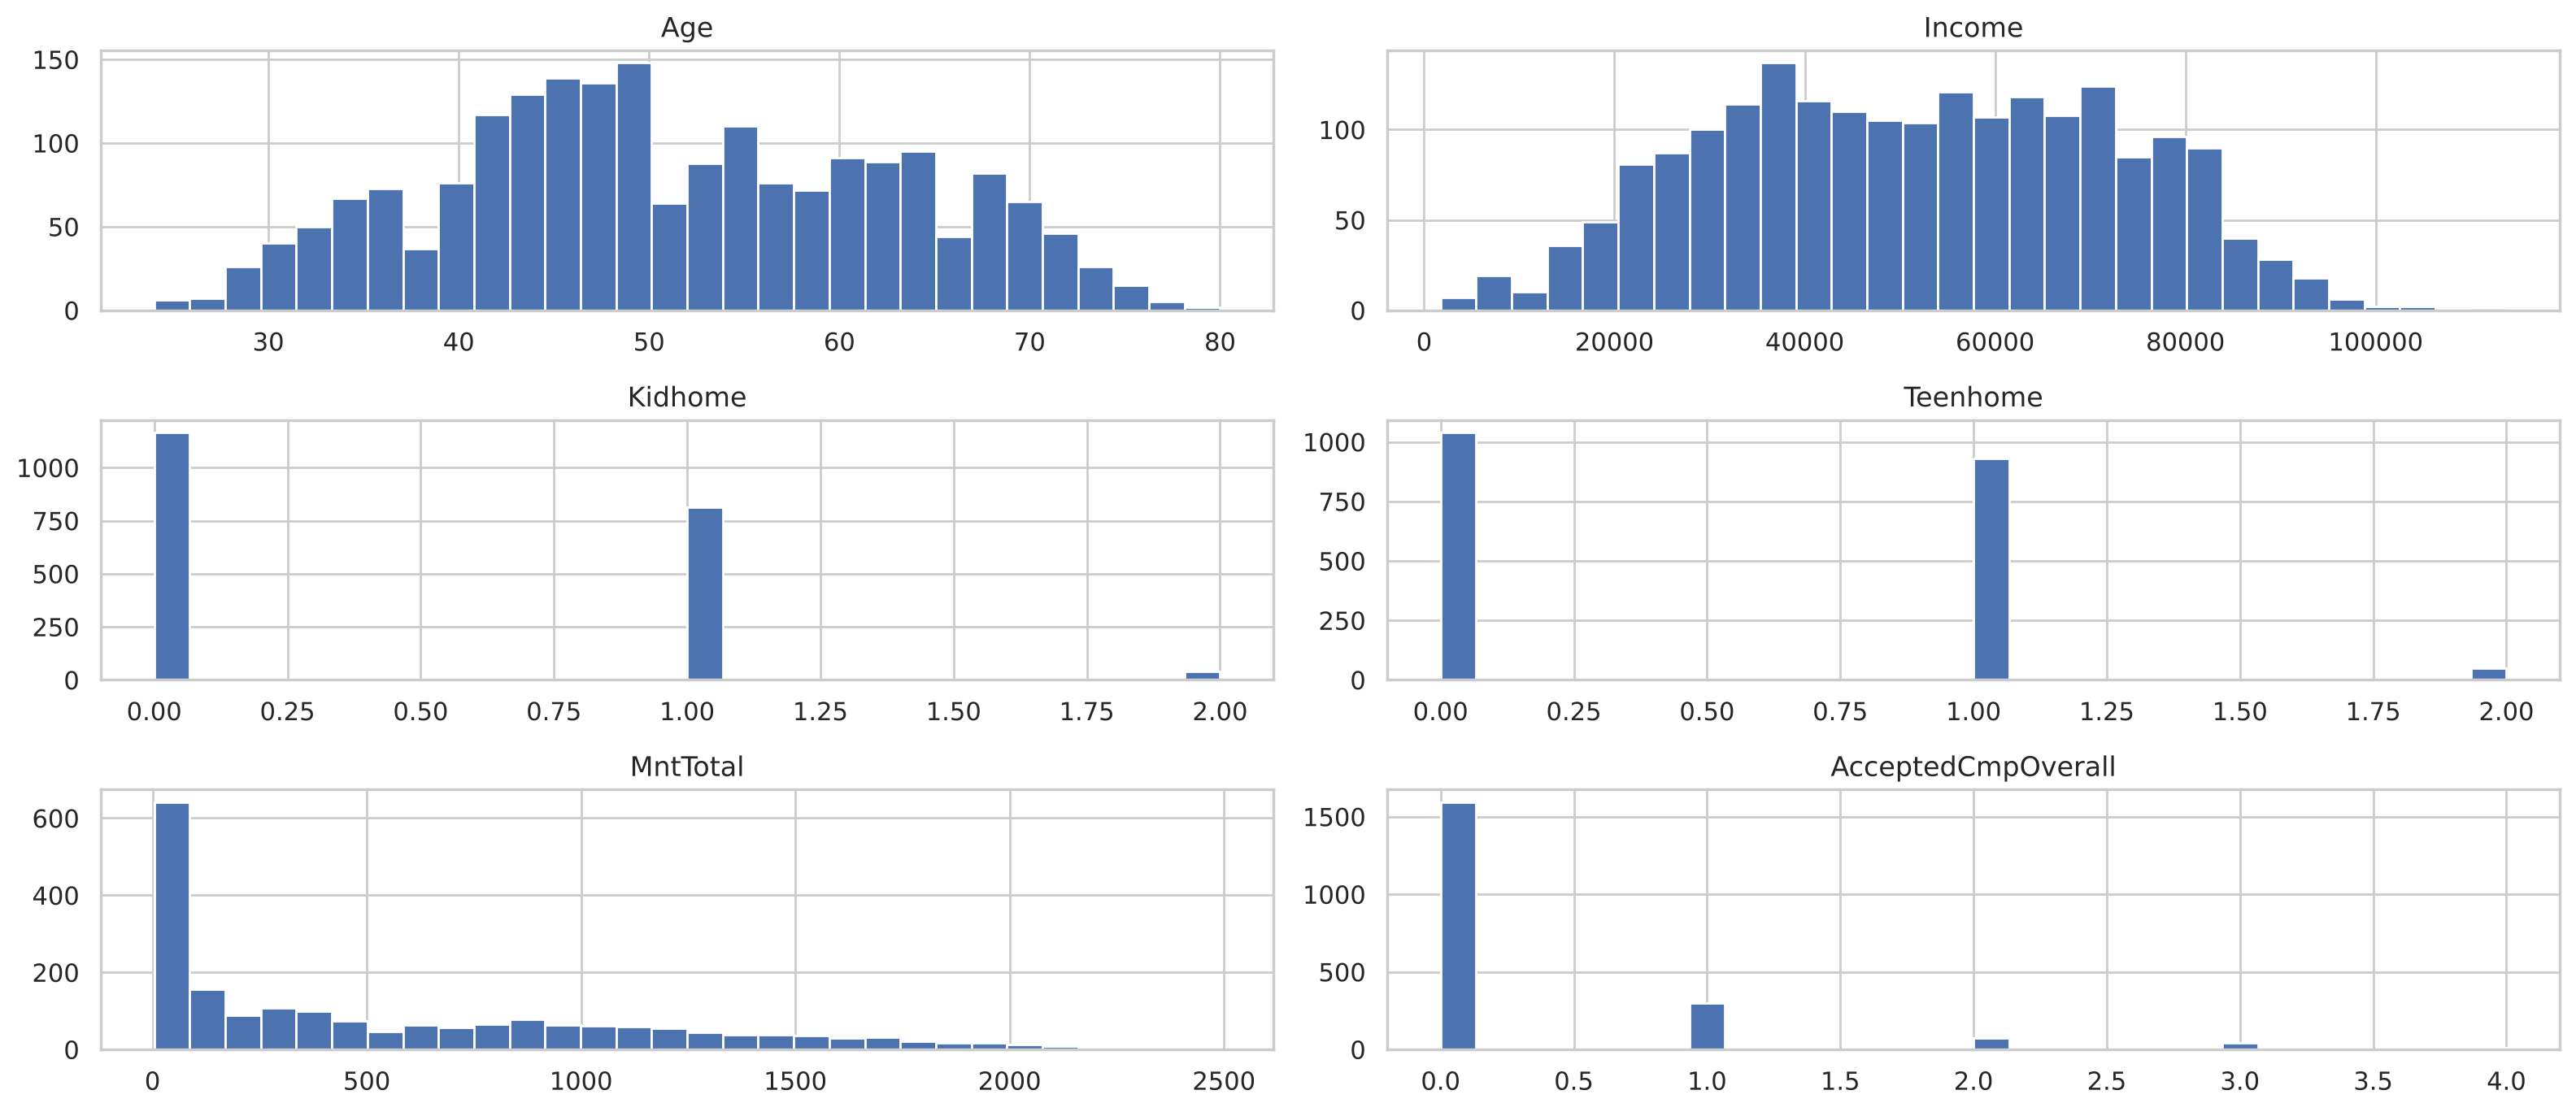

In [4]:
df.hist(column=["Age", "Income", "Kidhome", "Teenhome", "MntTotal", "AcceptedCmpOverall"],
        figsize=(16, 7), bins=30)
plt.tight_layout()
plt.show()

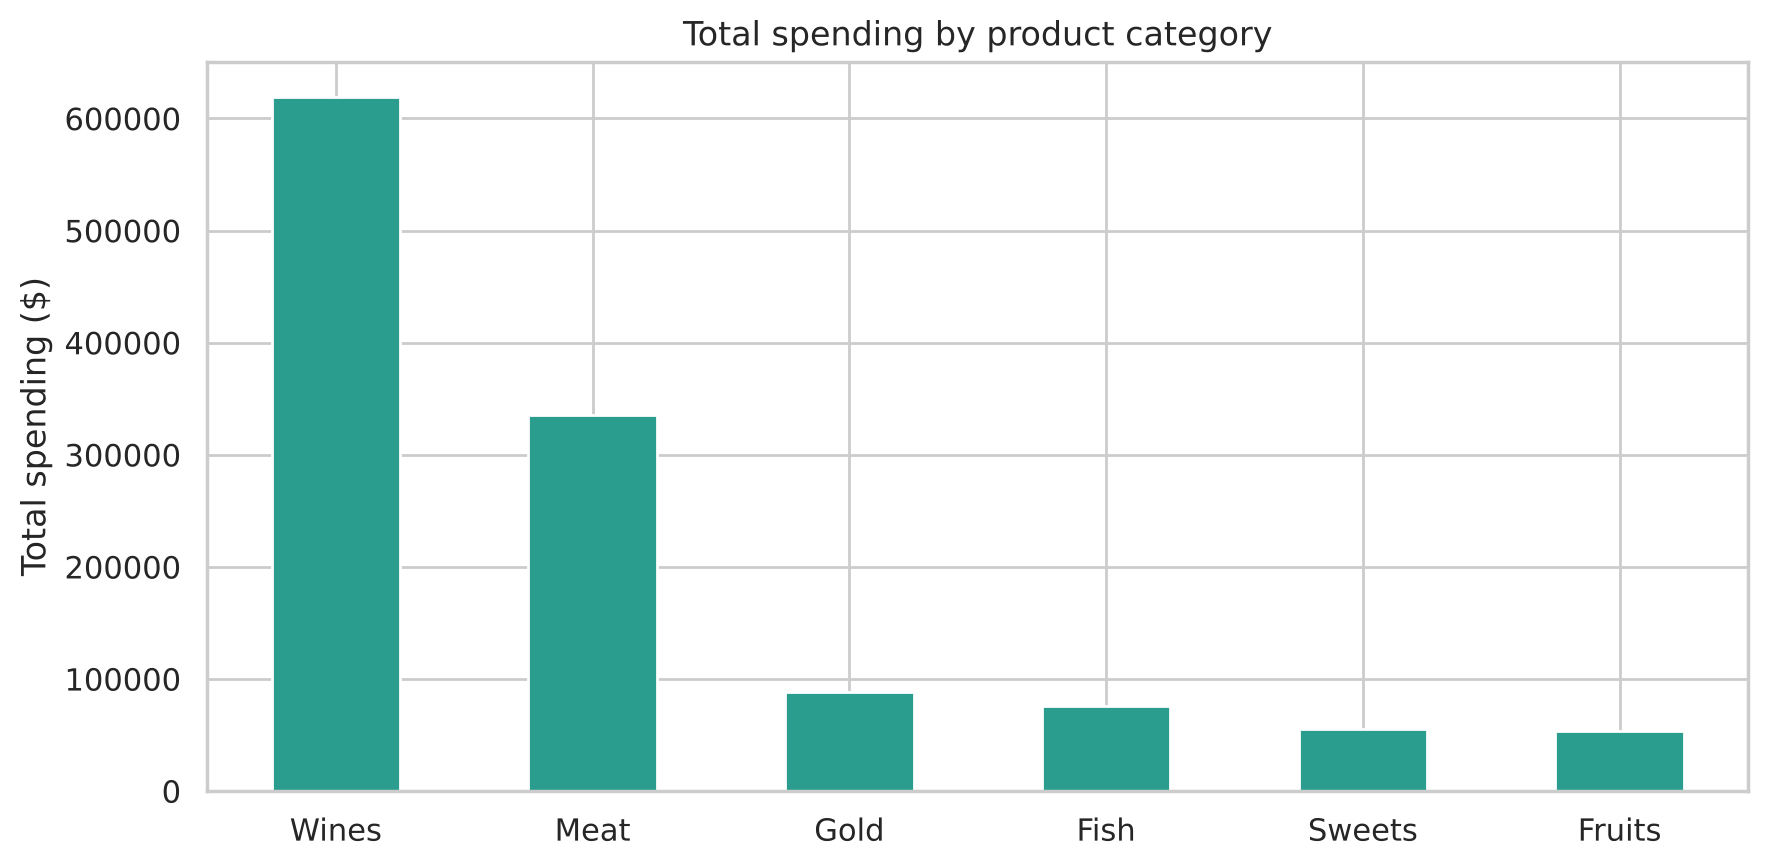

Share of total spending (%):
Wines     50.4
Meat      27.3
Gold       7.2
Fish       6.2
Sweets     4.5
Fruits     4.3

Average wine spending per customer: $306


In [5]:
spending = df[["Wines", "Meat", "Gold", "Fish", "Sweets", "Fruits"]].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
spending.plot(kind="bar", ax=ax, color="#2a9d8f")
ax.set_title("Total spending by product category")
ax.set_ylabel("Total spending ($)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("images/spending_by_category.png", dpi=120)
plt.show()

share = (spending / spending.sum() * 100).round(1)
print("Share of total spending (%):")
print(share.to_string())
print(f"\nAverage wine spending per customer: ${df['Wines'].mean():.0f}")

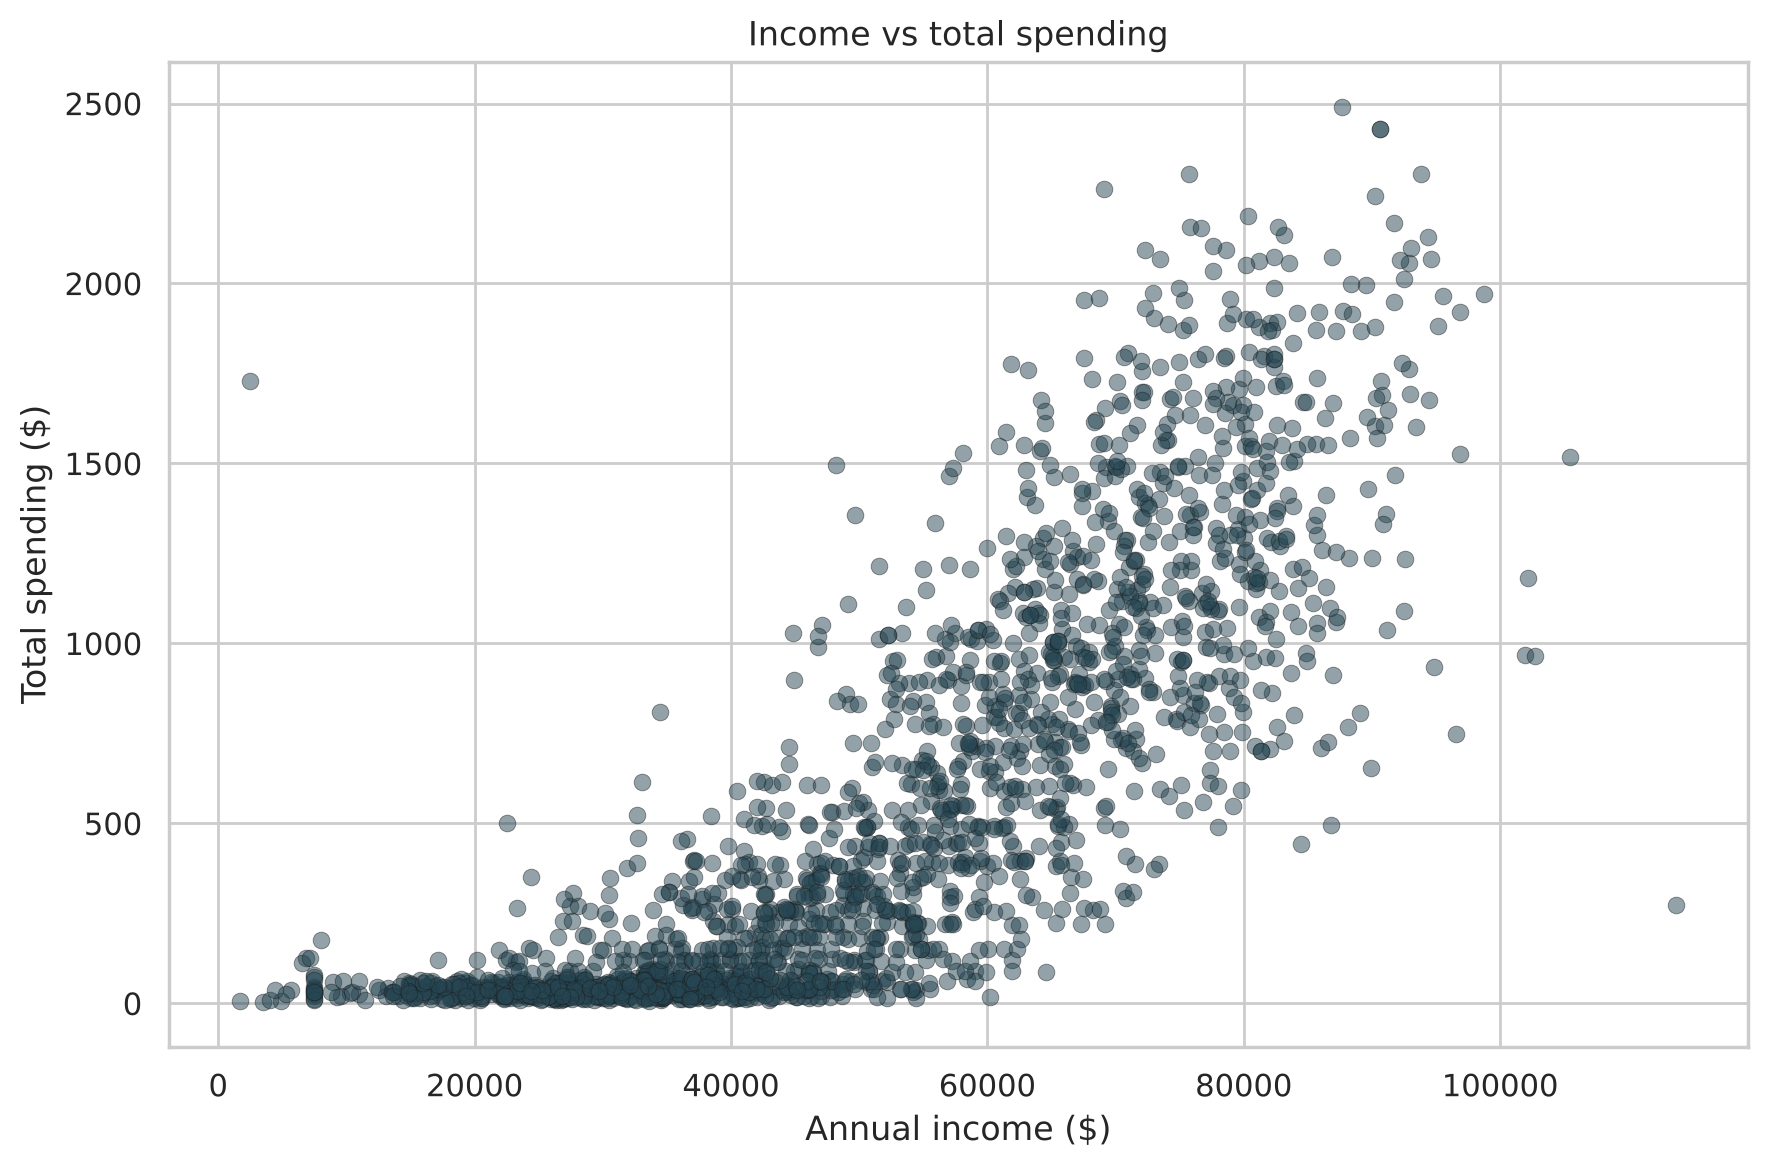

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df["Income"], df["MntTotal"], alpha=0.5, edgecolor="k", linewidth=0.3, color="#264653")
ax.set_title("Income vs total spending")
ax.set_xlabel("Annual income ($)")
ax.set_ylabel("Total spending ($)")
plt.tight_layout()
plt.savefig("images/income_vs_spending.png", dpi=120)
plt.show()

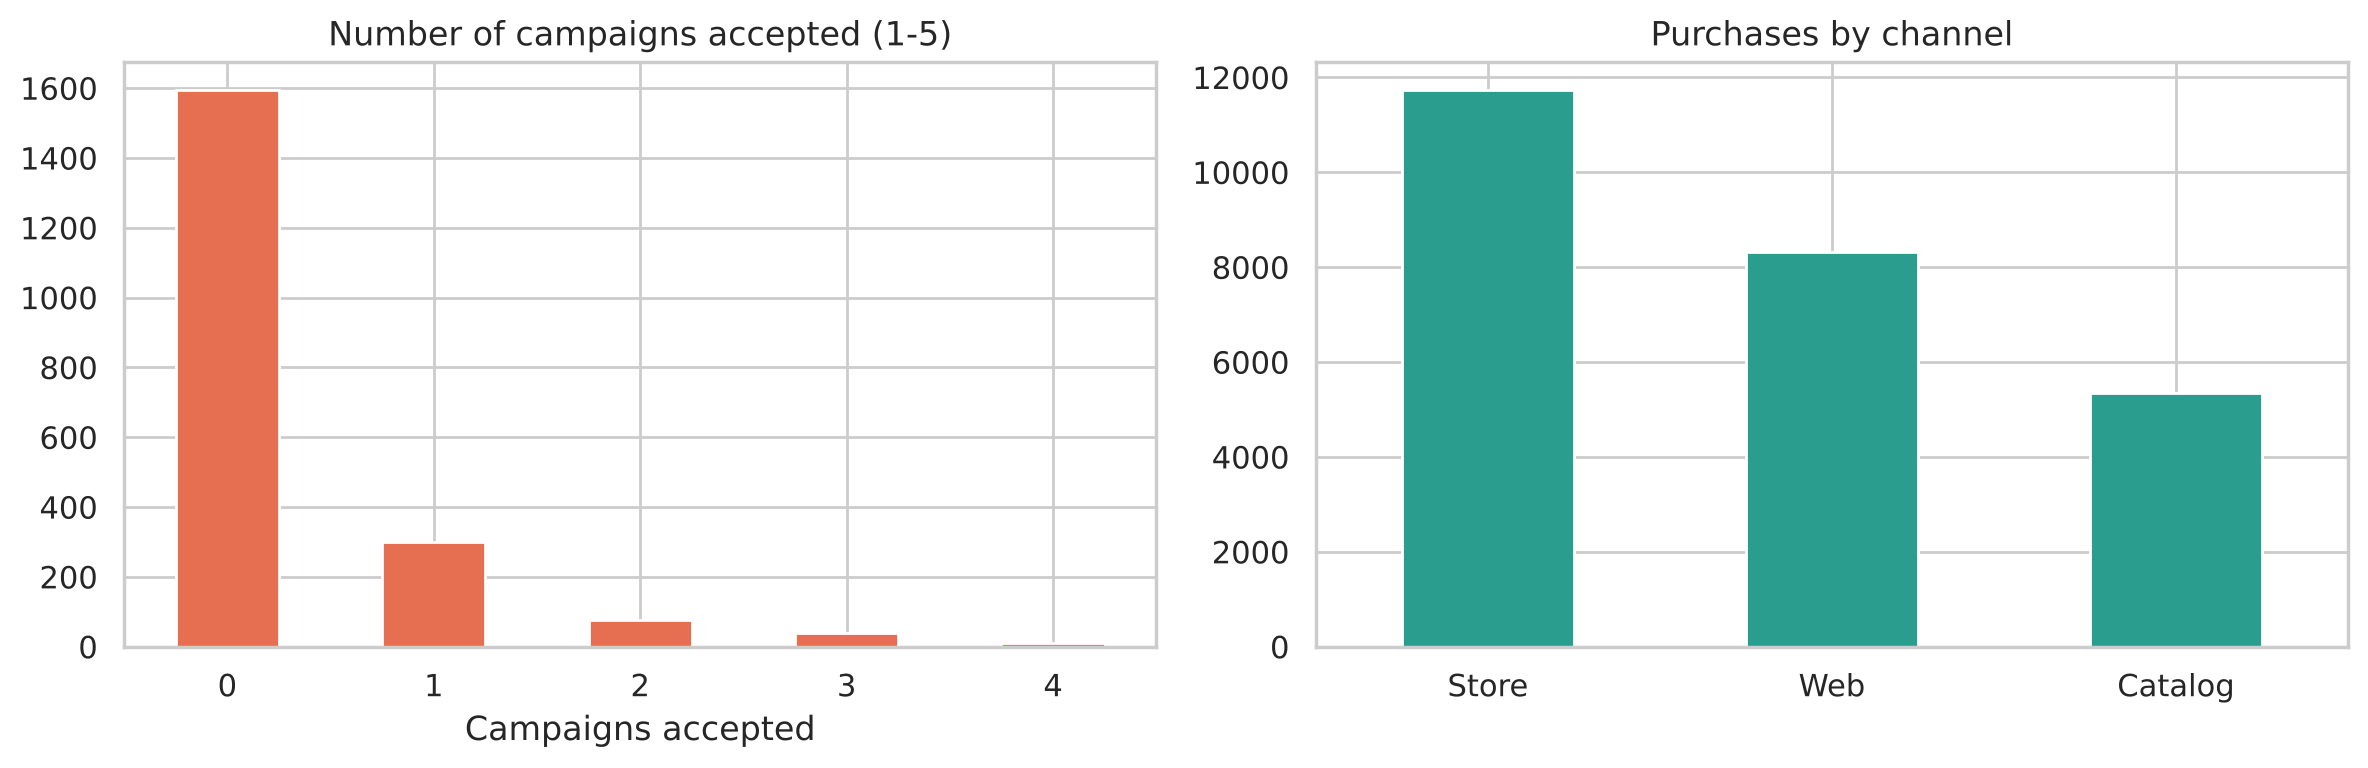

Customers who accepted none of campaigns 1-5: 78.9%
Customers who accepted the latest campaign (Response): 15.4%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["AcceptedCmpOverall"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#e76f51")
axes[0].set_title("Number of campaigns accepted (1-5)")
axes[0].set_xlabel("Campaigns accepted"); axes[0].tick_params(axis="x", rotation=0)

channels = df[["NumStorePurchases", "NumWebPurchases", "NumCatalogPurchases"]].sum()
channels.index = ["Store", "Web", "Catalog"]
channels.plot(kind="bar", ax=axes[1], color="#2a9d8f")
axes[1].set_title("Purchases by channel"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(f"Customers who accepted none of campaigns 1-5: {(df['AcceptedCmpOverall'] == 0).mean():.1%}")
print(f"Customers who accepted the latest campaign (Response): {df['Response'].mean():.1%}")

## 3. Correlation analysis

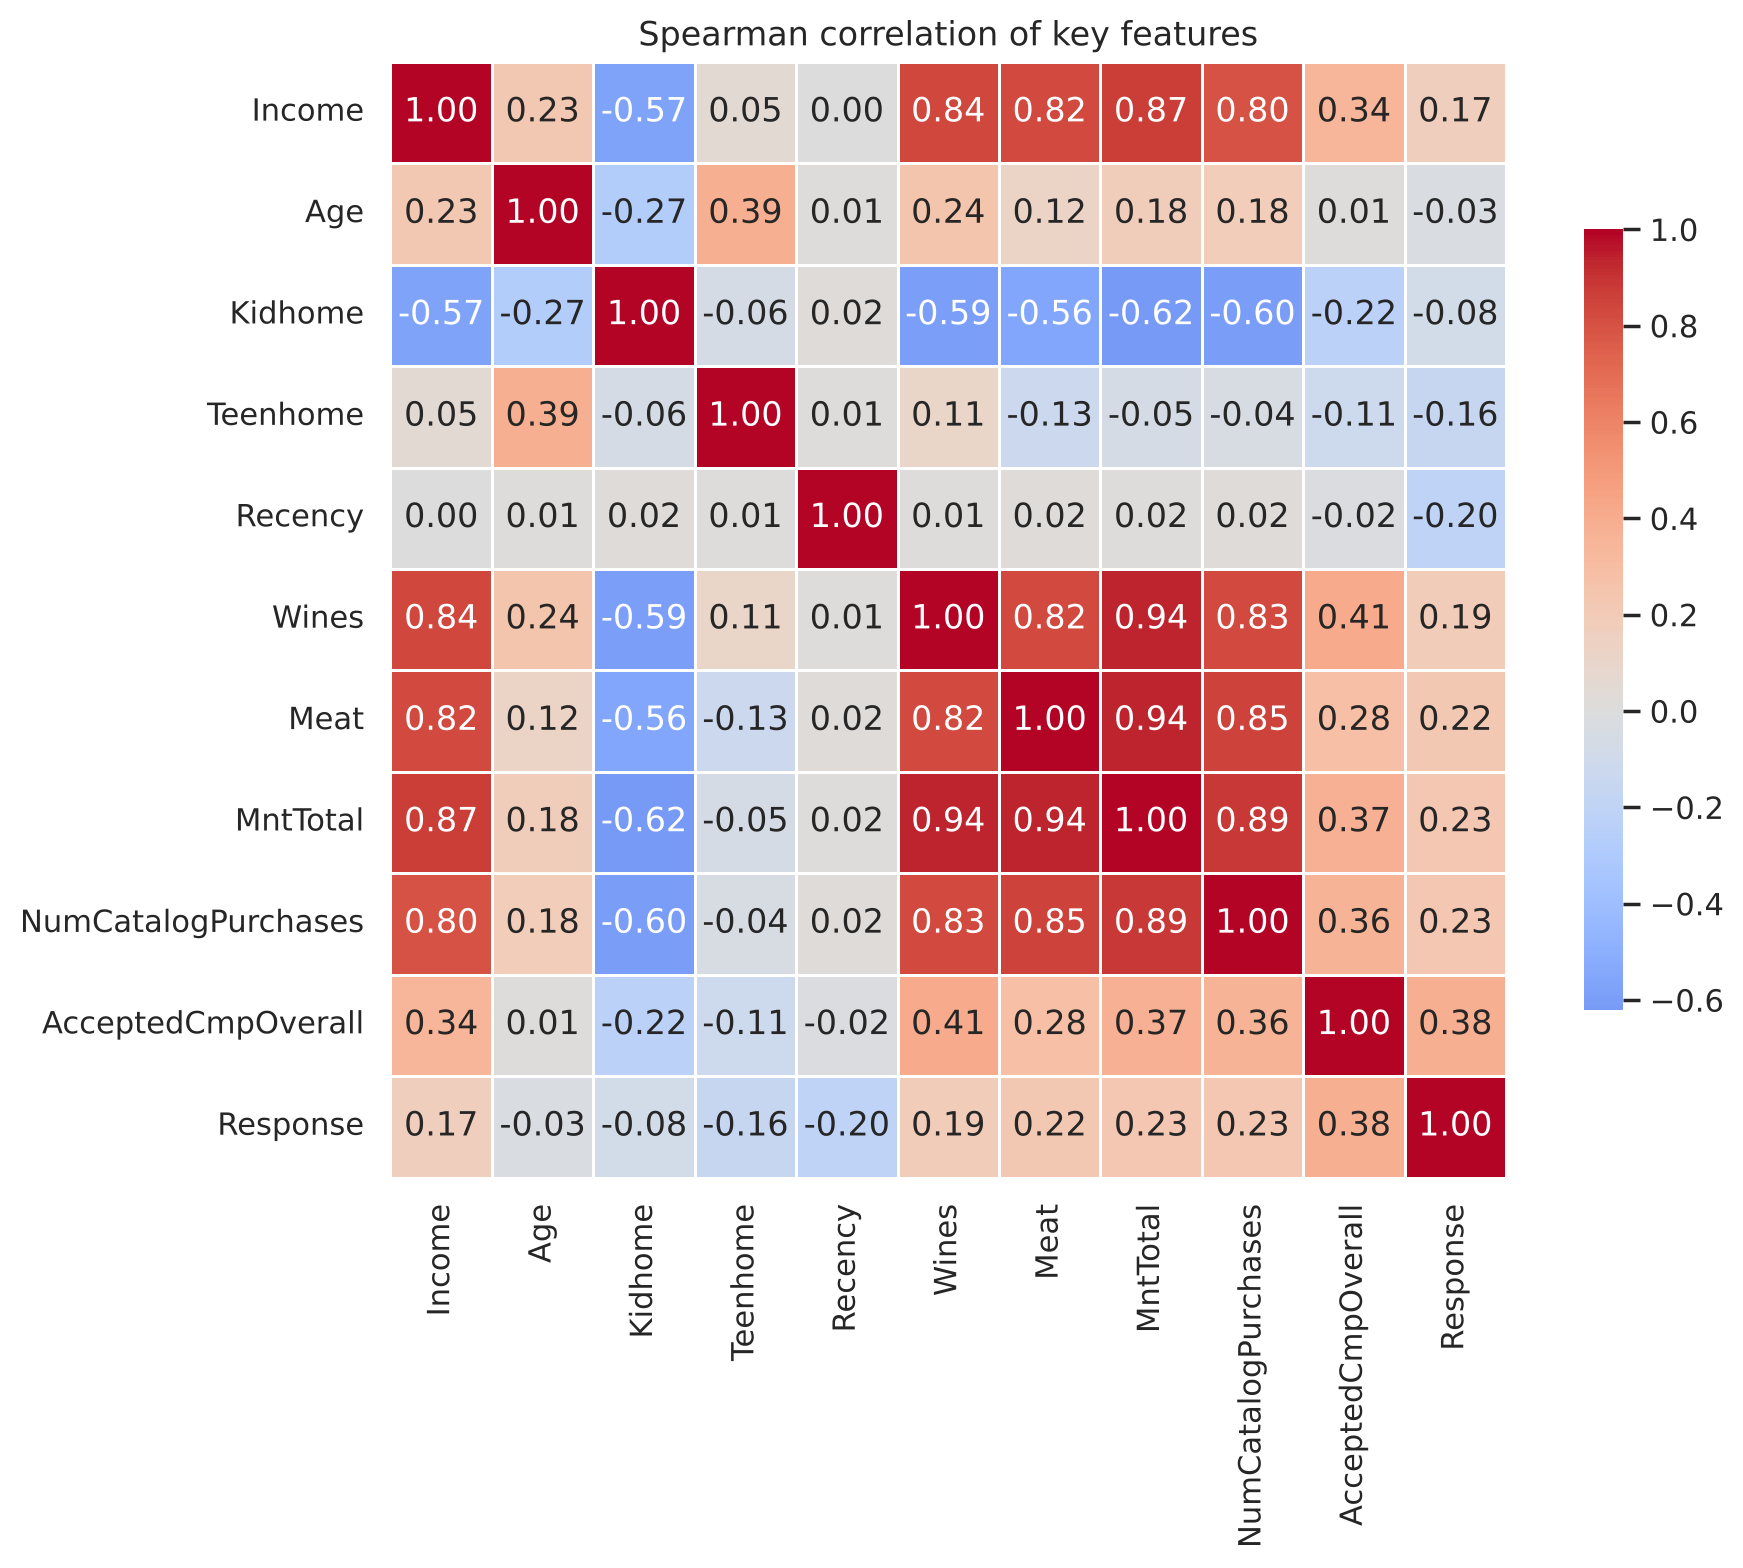

In [8]:
cols = ["Income", "Age", "Kidhome", "Teenhome", "Recency", "Wines", "Meat", "MntTotal",
        "NumCatalogPurchases", "AcceptedCmpOverall", "Response"]
corr = df[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation of key features")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=120)
plt.show()

**What the correlations show**
- Income is strongly linked to total spending, especially on wine and meat.
- Customers with children at home (`Kidhome`) spend much less.
- Accepting earlier campaigns and spending more are both positively linked to accepting the latest campaign (`Response`).
- Recency (days since last purchase) is negatively linked to `Response`: recent buyers respond more.

## 4. Customer segmentation (K-Means)

Features are standardized first so that large-scale columns such as Income do not dominate the distance calculation.

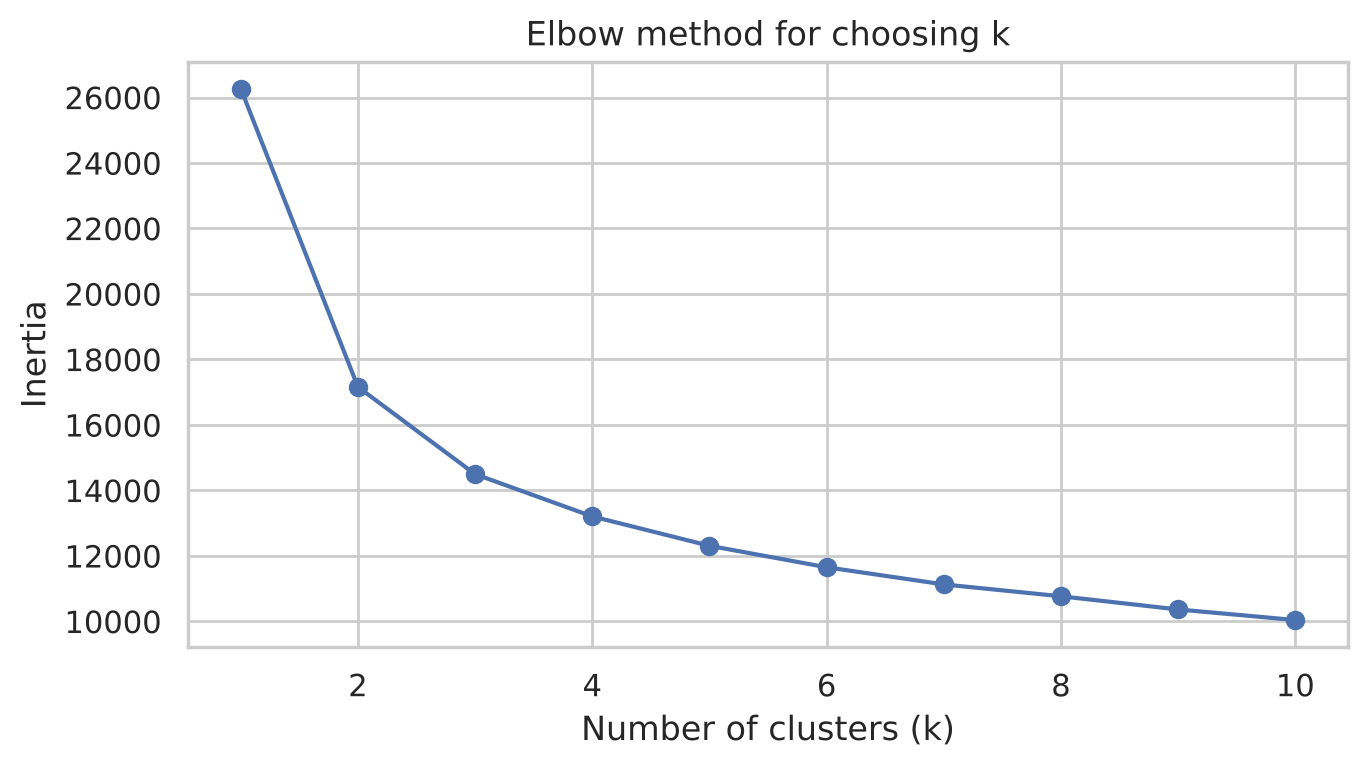

In [9]:
seg_features = ["Income", "Age", "Kidhome", "Teenhome", "Recency", "MntTotal", "Wines", "Meat",
                "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
                "NumWebVisitsMonth"]
X_seg = StandardScaler().fit_transform(df[seg_features])

inertia = [KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_seg).inertia_ for k in range(1, 11)]
plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow method for choosing k")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia")
plt.tight_layout()
plt.show()

In [10]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED)
df["Cluster"] = kmeans.fit_predict(X_seg)

profile = df.groupby("Cluster").agg(
    Customers=("Income", "size"),
    Avg_Income=("Income", "mean"),
    Avg_Spending=("MntTotal", "mean"),
    Kids_at_home=("Kidhome", "mean"),
    Teens_at_home=("Teenhome", "mean"),
    Web_visits_per_month=("NumWebVisitsMonth", "mean"),
    Engaged_rate=("Engaged", "mean"),
    Response_rate=("Response", "mean"),
).sort_values("Avg_Income", ascending=False).round(2)
profile

,Customers,Avg_Income,Avg_Spending,Kids_at_home,Teens_at_home,Web_visits_per_month,Engaged_rate,Response_rate
Cluster,,,,,,,,
1,476,76704.75,1351.96,0.03,0.10,2.74,0.45,0.31
2,613,58901.41,677.33,0.19,0.96,5.53,0.21,0.12
0,932,34165.15,86.57,0.82,0.43,6.54,0.09,0.10


## 5. Predicting campaign response

**Target:** `Response` = whether the customer accepted the most recent campaign (1) or not (0).

**Inputs:** income, demographics, spending, purchase channels, recency, and how many of the *earlier* campaigns (1-5) the customer accepted. The target itself is never used as an input.

**Baseline:** only about 15% of customers responded, so a model that always predicts "no" is already about 85% accurate. Accuracy alone is therefore misleading, so we also report **ROC-AUC** (how well the model ranks responders above non-responders, 0.5 = random) and **recall** (share of real responders the model finds).

**Validation:** 5-fold stratified cross-validation. The scaler is fitted on the training folds only, so no information from the test fold leaks into training.

In [11]:
FULL_FEATURES = ["Income", "Age", "Kidhome", "Teenhome", "Recency", "Customer_Days",
                 "Wines", "Meat", "Gold", "MntTotal", "NumDealsPurchases", "NumWebPurchases",
                 "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth", "AcceptedCmpOverall"]
TWO_FEATURES = ["Income", "AcceptedCmpOverall"]
y = df["Response"].values

def build_mlp(n_inputs):
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(n_inputs,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy")
    return model

def cross_validate(features, model_type="mlp", class_weighted=False):
    X = df[features].values.astype(float)
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    scores = []
    for train_idx, test_idx in folds.split(X, y):
        scaler = StandardScaler().fit(X[train_idx])
        X_train, X_test = scaler.transform(X[train_idx]), scaler.transform(X[test_idx])
        y_train, y_test = y[train_idx], y[test_idx]

        if model_type == "mlp":
            weights = None
            if class_weighted:
                w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
                weights = {0: w[0], 1: w[1]}
            model = build_mlp(X_train.shape[1])
            model.fit(X_train, y_train, epochs=60, batch_size=32, validation_split=0.2,
                      class_weight=weights, verbose=0,
                      callbacks=[tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
            prob = model.predict(X_test, verbose=0).ravel()
        else:
            model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
            prob = model.predict_proba(X_test)[:, 1]

        pred = (prob >= 0.5).astype(int)
        scores.append({
            "Accuracy": accuracy_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, prob),
            "Recall": recall_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
        })
    return pd.DataFrame(scores).mean()

In [12]:
baseline_acc = 1 - y.mean()
results = pd.DataFrame({
    "Baseline (always 'no')": pd.Series({"Accuracy": baseline_acc, "ROC-AUC": 0.5, "Recall": 0.0, "Precision": 0.0}),
    "Deep learning, 2 features": cross_validate(TWO_FEATURES),
    "Deep learning, all features": cross_validate(FULL_FEATURES),
    "Deep learning, all features + class weights": cross_validate(FULL_FEATURES, class_weighted=True),
    "Logistic regression, all features": cross_validate(FULL_FEATURES, model_type="logreg"),
}).T.round(3)
results

,Accuracy,ROC-AUC,Recall,Precision
Baseline (always 'no'),0.846,0.500,0.000,0.000
"Deep learning, 2 features",0.861,0.719,0.219,0.626
"Deep learning, all features",0.880,0.883,0.428,0.679
"Deep learning, all features + class weights",0.823,0.888,0.768,0.459
"Logistic regression, all features",0.885,0.883,0.421,0.716


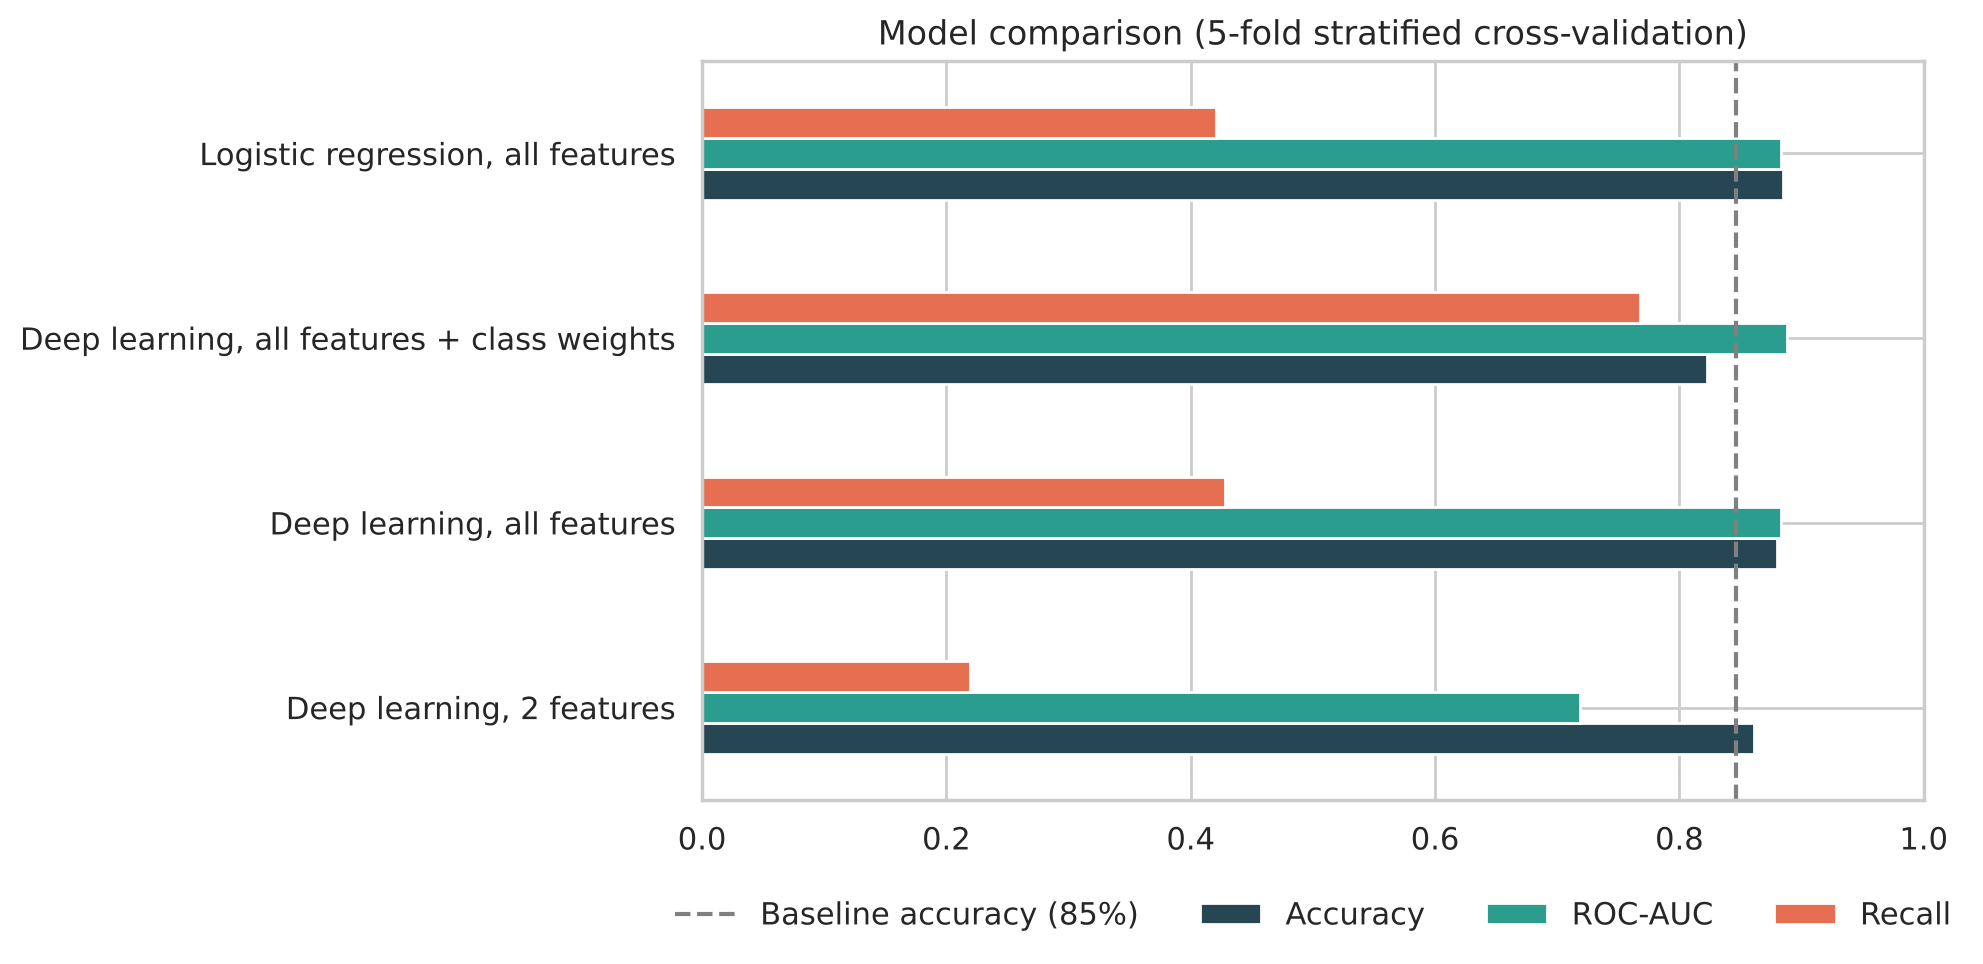

In [13]:
plot_df = results.drop(index="Baseline (always 'no')")[["Accuracy", "ROC-AUC", "Recall"]]
ax = plot_df.plot(kind="barh", figsize=(10, 5), color=["#264653", "#2a9d8f", "#e76f51"])
ax.axvline(baseline_acc, color="grey", linestyle="--", label=f"Baseline accuracy ({baseline_acc:.0%})")
ax.set_xlim(0, 1)
ax.set_title("Model comparison (5-fold stratified cross-validation)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=120)
plt.show()

**Reading the results**
- With only income and past campaign acceptance, the model barely beats the baseline, so two features are not enough.
- Using the full set of behavioral features gives a clearly better model (higher accuracy and ROC-AUC).
- Adding class weights lowers accuracy but finds far more of the real responders (higher recall). For marketing, this is usually the better trade: missing a likely buyer costs more than sending one extra offer.
- Logistic regression performs about as well as the deep learning model, so on a dataset this size a simple, explainable model is a good choice.

## 6. Findings and recommendations

**Findings**
1. Income is the main driver of spending, and wine and meat make up most of the revenue.
2. Households with children spend less and accept fewer campaigns.
3. Most customers have never accepted a campaign, but those who did once are much more likely to accept again.
4. Recent buyers and customers who buy through the catalog are more responsive.
5. K-Means found three segments: high-income customers with no kids (highest spending and response), mid-income families with teenagers, and lower-income families with young children (lowest spending and response).
6. A model using spending, recency, channel and past-campaign behavior ranks likely responders well (see ROC-AUC above).

**Recommendations**
- **Target the budget:** send campaigns to customers the model scores highest instead of everyone.
- **Bundle and upsell** around wine and meat, the top categories.
- **Design family-focused offers** (value packs, deals) for households with children, the least engaged group.
- **Act quickly:** contact customers soon after a purchase, while they are still responsive.

**Limitations**
- About 2,000 customers and only ~15% responders, so results may vary on new data.
- The data is a snapshot from one company; campaign content is unknown.